In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix
import time

# hp = keras_tuner.HyperParameters()

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def test_model(model, dataset):
    y_pred = model.predict(dataset, verbose=0)
    y_true = np.concatenate([y for x, y in dataset], axis=0)
    array = multilabel_confusion_matrix(y_true, y_pred.round())[1]
    return array

In [3]:
train_ds, valid_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_256_train/',
    labels='inferred',
    label_mode='categorical',
    batch_size=16,
    image_size=(256,256),
    validation_split=0.1,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_256_test/',
    labels='inferred',
    label_mode='categorical',
    batch_size=16,
    image_size=(256,256),
    seed=42,
    shuffle=False,
)

def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
train_ds = train_ds.map(process)
valid_ds = valid_ds.map(process)
test_ds = test_ds.map(process)

Found 119098 files belonging to 2 classes.
Using 107189 files for training.
Using 11909 files for validation.
Found 87687 files belonging to 2 classes.


In [5]:
model = keras.models.Sequential()
# Correct model
model.add(keras.Input(shape=(256,256,3)))

model.add(layers.Conv2D(filters=32, kernel_size=7, strides=2, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))

model.add(layers.Conv2D(filters=64,kernel_size=3, strides=2, activation='relu', padding='same'))
model.add(layers.Conv2D(filters=64,kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))

model.add(layers.Conv2D(filters=128,kernel_size=3, strides=2, activation='relu', padding='same'))
model.add(layers.Conv2D(filters=128,kernel_size=3, activation='relu', padding='same'))
model.add(layers.Flatten())

model.add(layers.Dense(units=128, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(units=64, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(units=2, activation='softmax'))


model.compile(
        loss=tf.keras.losses.categorical_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        metrics=[tf.keras.metrics.CategoricalAccuracy()]
    )

stop_early = tf.keras.callbacks.EarlyStopping(monitor="val_categorical_accuracy", patience=7, restore_best_weights=True)

In [6]:
start = time.time()
history = model.fit(
    train_ds.repeat(), 
    epochs=50,
    steps_per_epoch=5000,
    validation_data=valid_ds, 
    callbacks=[stop_early],
    class_weight={0: 0.25, 1: 1},
    )
endTime = time.time()-start
print(f'Time elapsed: {endTime//60}m {round(endTime%60,2)}s')

Epoch 1/50
5000/5000 [==============================] - 195s 38ms/step - loss: 0.0780 - categorical_accuracy: 0.9671 - val_loss: 0.1815 - val_categorical_accuracy: 0.9565
Epoch 2/50
5000/5000 [==============================] - 191s 38ms/step - loss: 0.0727 - categorical_accuracy: 0.9628 - val_loss: 0.1507 - val_categorical_accuracy: 0.9628
Epoch 3/50
5000/5000 [==============================] - 198s 40ms/step - loss: 0.0695 - categorical_accuracy: 0.9625 - val_loss: 0.1742 - val_categorical_accuracy: 0.9617
Epoch 4/50
5000/5000 [==============================] - 195s 39ms/step - loss: 0.0683 - categorical_accuracy: 0.9628 - val_loss: 0.1205 - val_categorical_accuracy: 0.9630
Epoch 5/50
5000/5000 [==============================] - 204s 41ms/step - loss: 0.0667 - categorical_accuracy: 0.9630 - val_loss: 0.1376 - val_categorical_accuracy: 0.9538
Epoch 6/50
5000/5000 [==============================] - 194s 39ms/step - loss: 0.0611 - categorical_accuracy: 0.9614 - val_loss: 0.1304 - val_cat

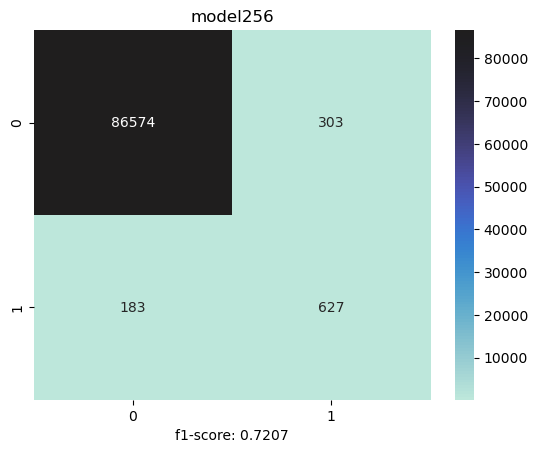

In [7]:
# model = keras.models.load_model('./trained_models/model256')
array = test_model(model, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model256')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.savefig('./documentation/model256_test.png')
plt.show()

In [8]:
model.save('./trained_models/model256_test')

INFO:tensorflow:Assets written to: ./trained_models/model256_test\assets


INFO:tensorflow:Assets written to: ./trained_models/model256_test\assets


In [4]:
model256 = keras.models.load_model('./trained_models/model256')
model256.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 32)      4736      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64, 64, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 64)        18496     
                                                                 
 conv2d_2 (Conv2D)           (None, 32, 32, 64)        36928     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 16, 16, 64)       0         
 2D)                                                             
                                                                 
 conv2d_3 (Conv2D)           (None, 8, 8, 128)         7

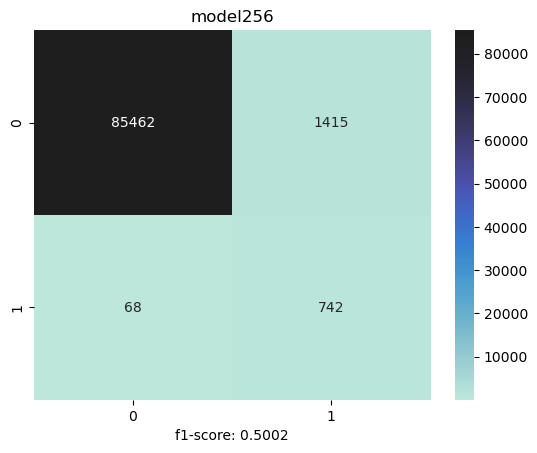

In [5]:
array = test_model(model256, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model256')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.savefig('./documentation/model256.png')
plt.show()